In [1]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from utils import significance,adjust_box_widths
from matplotlib.patches import PathPatch
from matplotlib.path import Path

In [100]:
boxplot1 = [67, 72, 68, 75, 71] 
boxplot2 = [65, 64, 67, 68.2, 72] #Spatial
boxplot3 = [62.7, 61.5, 65, 60.8, 67.7]
boxplot4 = [53.5, 57, 52.7, 49.2, 45.8] #Trial

boxplots = [boxplot1,boxplot2,boxplot3,boxplot4]
#boxplots = [boxplot1,boxplot2]

In [101]:
print(np.mean(boxplot1))
print(np.mean(boxplot2))

70.6
67.24


In [102]:
data = []

for i,el in enumerate(boxplots):
    fh = 0 if i < 2 else 1
    odd = 0 if i%2==0 else 1
    for value in el:
        data.append([f'boxplot{odd}',value,fh])
df = pd.DataFrame(data,columns=['boxplot','value','first_half'])

In [103]:
def map_half(i,num):
    return 0 if i<num/2 else 1

In [104]:
def marker(filled=False):
    if (filled):
        return 'o'
    pts = np.linspace(0, np.pi * 2, 24)
    circ = np.c_[np.sin(pts) / 2, -np.cos(pts) / 2]
    vert = np.r_[circ, circ[::-1] * .7]
    return Path(vert)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


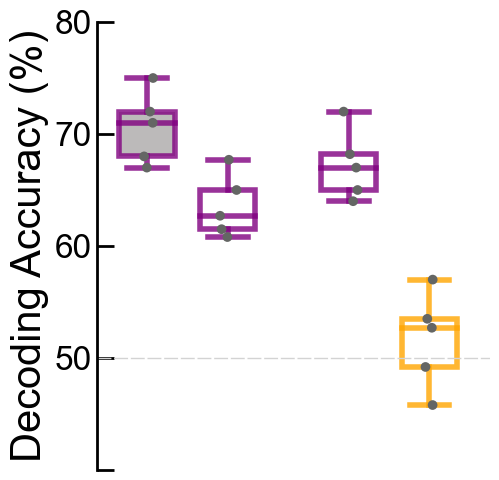

In [109]:
PROPS = {
    'boxprops':{'facecolor':'none', 'edgecolor':'mediumblue','alpha': 0.8},
    'medianprops':{'color':'cornflowerblue','alpha': 0.8},
    'whiskerprops':{'color':'cornflowerblue','alpha': 0.8},
    'capprops':{'color':'cornflowerblue','alpha': 0.8}
}

text_boxplot = ['','']
#colors = ["#646664","#646664"]
colors = ["#646664","#646664"]
colors_boxplot = ['purple', 'purple', 'purple', 'orange']


colors_boxplot_filling = ['#aba9a9',"#aba9a9"]
colors_boxplot_filling = ['#aba9a9',"white"]



ax = sns.stripplot(
    data=df,
    hue='first_half',
    y='value',
    x='boxplot',
    marker=marker(True),
    palette=colors,
    size=7,
    jitter=0.09,
    dodge=True
)


locs = ["upper left"]
boxplot = sns.boxplot(
    data=df,
    hue='first_half',
    y='value',
    x='boxplot',
    palette=colors_boxplot,
    fliersize=0,
    linewidth=4,
    **PROPS
)
#plt.axhline(linewidth=2, color='lightgrey',ls='--', y=50)

plt.axhline(y=50,linewidth=1, color='lightgrey',ls='--', dashes=(10, 2))


data_ratio = 0.4016222222466667

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)


#CHANGE BOXPLOT STYLE

box_patches = [patch for patch in boxplot.patches if type(patch) == matplotlib.patches.PathPatch]
if len(box_patches) == 0:  # in matplotlib older than 3.5, the boxes are stored in ax2.artists
    box_patches = boxplot.artists
    
num_patches = len(box_patches)
lines_per_boxplot = len(boxplot.lines) // num_patches

for i, patch in enumerate(box_patches):
    
    col = colors_boxplot[i]
    col_fill = colors_boxplot_filling[map_half(i,len(box_patches))]
    facecolor = col_fill if i%2==0 else 'None'
    patch.set_edgecolor(col)
    patch.set_facecolor(facecolor)
    
    for line in boxplot.lines[i * lines_per_boxplot: (i + 1) * lines_per_boxplot]:
        line.set_color(col)

       
        
#END CHANGE BOXPLOT STYLE

        

#handles, labels = ax.get_legend_handles_labels()
#l = plt.legend(handles[0:2], ["", ""],loc=2)

plt.legend([],[], frameon=False)

ax.set_xticklabels([], fontsize = 26)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)
ax.spines['left'].set_color('black')


ax.set_xlabel("",fontsize=20)

### modified
ax.set_ylim(bottom=40,top=80);
ax.set_yticks([40,50,60,70,80], fontname='Arial')
ax.set_yticklabels(['', '50','60','70','80'],fontname='Arial')


ax.set_xticks('')

ax.spines['left'].set_color('black')
ax.spines['left'].set_linewidth(2)

plt.legend([],[], frameon=False)

#plt.title('CCGP', fontname = 'Arial', fontsize = 22)


ax.set_xlabel("",fontsize=20)
ax.set_ylabel('Decoding Accuracy (%)', fontsize = 30, fontname='Arial')

ax.set_xlim([-0.45,1.5])

#significance(ax,0,data_ratio,newdf.loc[newdf['control']=='y']['Left preference'].max()+17,text=text_boxplot[0],offset=-4,whisker=4)
significance(ax,1,data_ratio,df.loc[df['boxplot']=='boxplot1']['value'].max()+20,text=text_boxplot[1],offset=-4,whisker=4)


fig = ax.get_figure()
adjust_box_widths(fig, 0.7)
fig.set_size_inches(5.1,4.9)
ax.tick_params(axis='y', which='major', direction='in',length=12, labelsize=24, width=2)

plt.setp(boxplot.patches, linestyle='-')
plt.tight_layout()
fig.tight_layout()
fig.savefig("CCGP_Valence_Position.jpg",dpi=600,bbox_inches='tight')
plt.savefig('CCGP_Valence_Position.eps', format='eps', dpi=600)

